# Linear Regression: Salary Prediction

This notebook demonstrates how Linear Regression can be used to predict salary based on years of work experience. The goal is to build a simple regression model, evaluate its predictions, and visualize the results.

## 1. Import Libraries and Create the Dataset

We begin by importing the required Python libraries:
- **Pandas** and **NumPy** for data handling and numerical calculations.
- **Matplotlib** for visualizing the data and model results.
- **Scikit-learn** for splitting the data, training the Linear Regression model, and evaluating its performance.

Next, we create a small sample dataset containing years of experience and corresponding salaries.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Creating a sample dataset
data = {
    'Experience': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Salary': [21000, 24500, 31500, 33000, 41500,
               44000, 52000, 53500, 61500, 66000]
}

df = pd.DataFrame(data)

print(df.head())

   Experience  Salary
0           1   21000
1           2   24500
2           3   31500
3           4   33000
4           5   41500


## 2. Define the Features and Target

In this step, we separate the dataset into:
- **Feature (X):** Years of experience, which the model uses to make predictions.
- **Target (y):** Salary, which the model aims to predict.

In [2]:
X = df[['Experience']]
y = df['Salary']

## 3. Split the Dataset

We divide the data into training and testing sets. The model learns from the training data, while the testing data is used to evaluate how well it predicts unseen observations.

Here, 80% of the data is used for training and 20% for testing. `random_state=42` makes the split reproducible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 4. Create and Train the Linear Regression Model

We create a Linear Regression model and train it using the training data. During training, the model estimates the relationship between years of experience and salary by fitting a best-fit line.

In [4]:
model = LinearRegression()

model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## 5. Make Predictions

After training, we use the model to predict salaries for the experience values in the test set. These predictions can then be compared with the actual salaries.

In [5]:
y_pred = model.predict(X_test)

print(y_pred)

[60146.55172414 25478.44827586]


## 6. Evaluate Model Performance

We evaluate the predictions using four common regression metrics:
- **MAE:** Average absolute difference between actual and predicted values.
- **MSE:** Average squared prediction error.
- **RMSE:** Square root of MSE, expressed in the target variable's units.
- **R² Score:** Indicates how much of the variation in the target is explained by the model.

A lower MAE, MSE, and RMSE generally indicate smaller prediction errors. An R² value closer to 1 indicates a stronger fit, but metrics should be interpreted in the context of the dataset size.

In [6]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1165.9482758620725
MSE: 1394591.6319857393
RMSE: 1180.928292482545
R2 Score: 0.9959252253265574


## 7. Visualize the Regression Line

The scatter plot displays the training and testing observations. The red line represents the salary values predicted by the trained Linear Regression model across the experience values.

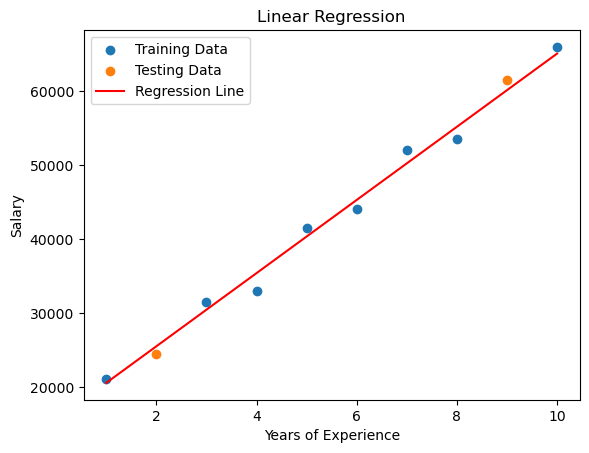

In [7]:
plt.scatter(X_train, y_train, label='Training Data')

plt.scatter(X_test, y_test, label='Testing Data')

plt.plot(
    X,
    model.predict(X),
    color='red',
    label='Regression Line'
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")

plt.title("Linear Regression")
plt.legend()
plt.show()

## 8. Analyze the Residuals

A residual is the difference between an actual value and its predicted value. This plot compares the model's training predictions with their residuals.

Ideally, residuals should be scattered around zero without a clear pattern. Since this example contains only 10 observations, the plot is useful for demonstration but is too small to support strong conclusions about model assumptions.

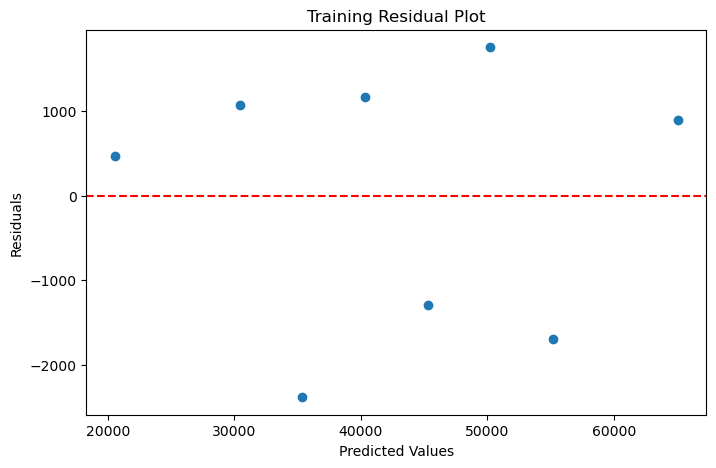

In [9]:
# Training predictions
y_train_pred = model.predict(X_train)

# Calculate residuals
train_residuals = y_train - y_train_pred

# Residual plot
plt.figure(figsize=(8, 5))

plt.scatter(y_train_pred, train_residuals)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Training Residual Plot")

plt.show()

## Conclusion

This project demonstrates the basic workflow of a Linear Regression model: preparing the data, splitting it into training and testing sets, training the model, making predictions, evaluating performance, and visualizing the results.

The dataset is small and created for learning purposes. A real-world salary prediction project would require a larger, representative dataset and additional relevant features such as education, job role, location, and industry.